# 01 · Gene search (RBP-ARK)

Which RNA-binding proteins (RBPs) bind PICALM, and where? RBP-ARK's gene search lists their reproducible enriched windows. A window is a stretch of about 100 nt where the eCLIP signal of an RBP is higher than in its size-matched input, in both replicates.

This notebook shows the search in the browser, then runs the same search in code. Notebook 02 then looks at the QKI experiments one by one.

On Google Colab, run the next cell first in every session. It copies this repository onto the Colab machine and, with `SAVE_TO_DRIVE = True`, saves results and the figure to `My Drive/CS3_workflow` (Colab asks for permission to connect your Drive). `LITE = True` uses a small subset of the data that fits free Colab. On your own computer the cell does nothing.

In [ ]:
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess
    REPO = "https://github.com/yeolab/encode-rbp-case-study"
    CLONE = "/content/encode-rbp-case-study"
    LITE = True    # True: small subset of the data, fits free Colab (about 1 h). False: all the data (5-8 h, ~50 GB)
    SAVE_TO_DRIVE = True    # results and the figure in My Drive/CS3_workflow; False: on this Colab machine only
    if not os.path.isdir(CLONE):
        subprocess.run(["git", "clone", "-q", "--depth", "1", REPO, CLONE], check=True)
    WORKFLOW = CLONE + "/notebooks/workflow"
    OUTPUT = None
    if SAVE_TO_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
        OUTPUT = "/content/drive/MyDrive/CS3_workflow"
    sys.path.insert(0, WORKFLOW)
    import colab_setup
    colab_setup.setup(WORKFLOW, lite=LITE, output_folder=OUTPUT)

## In the browser

1. Open [rbp-ark.com/genesearch](https://rbp-ark.com/genesearch/), type PICALM and keep the minimum enrichment at ≥ 3 (mean log2 fold over input). The By RBP tab ranks the 120 experiments with a window on PICALM by their number of windows.

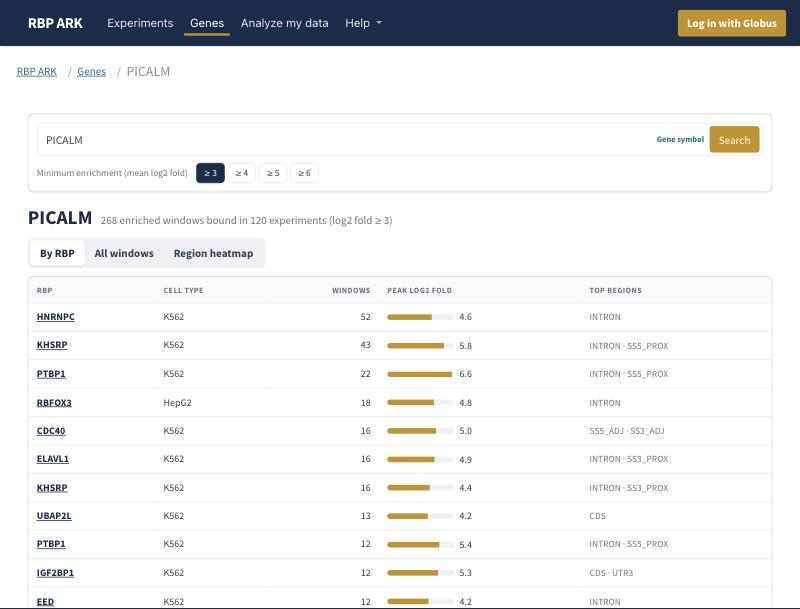

2. Open the All windows tab and type QKI in the filter box under Experiment. Both K562 experiments have a window at 85,990,399-85,990,499, next to the 150-nt exon, and all three have one at 85,977,969-85,978,068, next to the 24-nt exon.

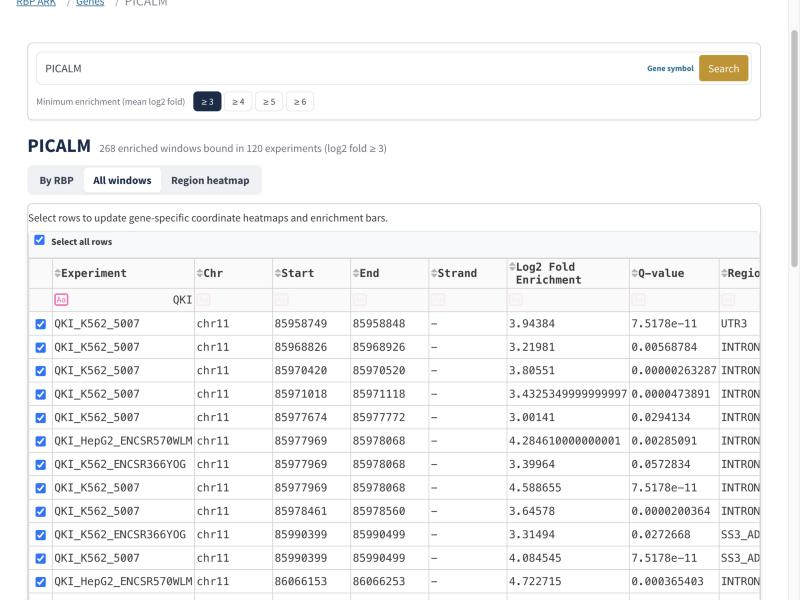

3. Scroll down to the coordinate view, pick "Selected gene, all isoforms", and drag across the plot to zoom in on 85,976,000-85,992,500. The top rows are PICALM's transcripts and the bottom rows the QKI windows. PICALM is on the minus strand, so it is read from right to left here.

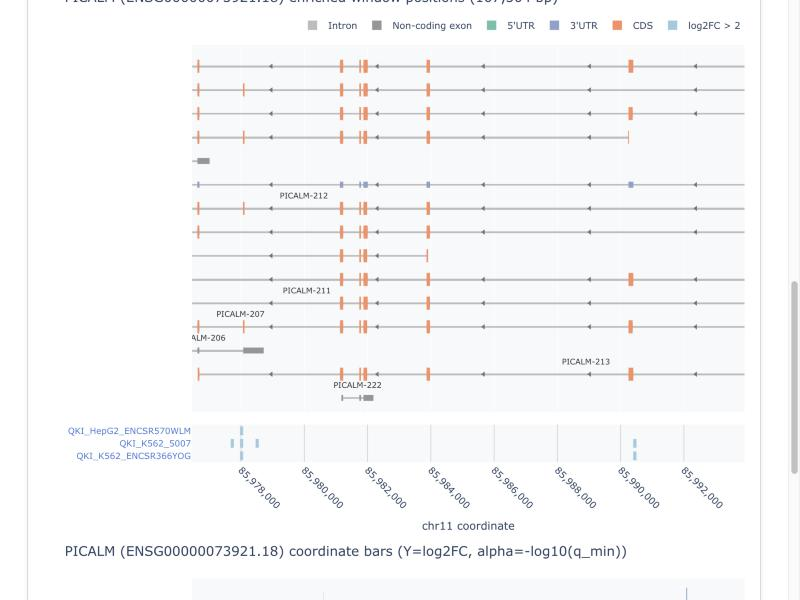

## The same search in code

The gene search page reads RBP-ARK's public API. `gene_search()` asks `/api/genes/PICALM/experiments/?min_enrichment=3` and returns one row per window and experiment.

In [ ]:
import json
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

sys.path.insert(0, ".")
import workflow_utils as U

ROOT, DATA = U.folders()
RESULTS = ROOT / "results" / "workflow"
API_CACHE = DATA / "downloads" / "rbpark_api"
print("case study folder:", ROOT)
print("data folder:", DATA)

In [ ]:
hits = U.gene_search(U.GENE, API_CACHE, min_enrichment=3)
print(hits["subject"].nunique(), "experiments,", len(hits), "windows on", U.GENE)
hits.groupby(["subject", "rbp"]).size().sort_values(ascending=False).head(10).rename("windows")

The QKI windows, with each window's position next to the two exons. Positions count like intron nucleotides: −1 is the last nucleotide before an exon's 3′ splice site, +1 the first one after its 5′ splice site.

In [ ]:
qki = hits[hits["rbp"] == U.RBP].copy()
for exon, info in U.EXONS.items():
    qki["nt from " + info["name"]] = [U.relative_position(s, e, exon) for s, e in zip(qki["start"], qki["end"])]
qki.to_csv(RESULTS / "01_gene_search_PICALM.tsv", sep="\t", index=False)
qki[["subject", "start", "end", "feature_type", "log2_enrichment", "q_value", "nt from 150-nt exon", "nt from 24-nt exon"]]

Two windows sit right next to the exons: one ending 1 nt before the 150-nt exon (both K562 experiments) and one starting 2 nt after the 24-nt exon (all three). The HepG2 experiment also has a window before the 150-nt exon, but below the search's cutoff of 3 (notebook 02). Notebook 07 checks whether these positions match what QKI does across the genome.